# Quand le pétrole bouge, qu'arrive-t-il aux coûts d'un manufacturier de revêtements de sol ?

**Transmission des chocs pétroliers aux intrants pétrochimiques : ce que 16 ans de données de Statistique Canada nous apprennent, et ce que la guerre en Iran (février 2026) a confirmé en temps réel.**

Ce carnet accompagne l'article publié sur LinkedIn. Il contient toute la partie technique : construction de la base, détection des régimes, décalages, tests, validation hors échantillon. Chaque chiffre de l'article se retrouve ici.

### La question

Un manufacturier de revêtements de sol achète du polypropylène, du nylon, du polyester, du latex. Presque tout dépend, de près ou de loin, du pétrole. Mais **avec quel délai, et avec quelle force** ? Et surtout : un acheteur a-t-il le temps d'agir entre le moment où le baril bondit et celui où la facture de résine arrive ?

### Ce que le carnet démontre, en bref

1. **Les produits pétrochimiques suivent le pétrole avec environ 1 mois de retard** (corrélation de 0,50 à un mois).
2. **Les résines plastiques aussi, et le lien se resserre** : 0,31 avant 2020, 0,66 depuis 2021.
3. **Le caoutchouc synthétique (latex)** réagit plus lentement (≈ 2 mois), avec un lien modéré.
4. **Les fibres synthétiques** : aucun lien stable avec le pétrole.
5. **Depuis février 2020, les résines sont dans un régime durablement plus volatil** : écart-type mensuel de 1,2 % avant, 5,7 % depuis.
6. **Test grandeur nature** : le choc de mars 2026 (guerre en Iran, détroit d'Ormuz) a fait monter le WTI en dollars canadiens de 59 % en trois mois. Les résines ont suivi, avec un décalage, et de façon bien plus violente que l'histoire ne le laissait prévoir.

> **Honnêteté d'abord.** Ce sont des corrélations et des précédences statistiques, pas des preuves de causalité. Les chocs pétroliers extrêmes sont rares dans l'échantillon (5 mois sur 199). Un mois de décalage n'est pas une garantie : c'est un ordre de grandeur utile pour décider.

## 0. Préparation

On charge les bibliothèques et on fixe quelques réglages d'affichage. Rien d'exotique : `pandas` pour les données, `statsmodels` pour les tests, `hmmlearn` pour les régimes.

In [1]:
# Si hmmlearn n'est pas installé : !pip install hmmlearn statsmodels
import os, io, json, warnings, contextlib
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import statsmodels.api as sm
from statsmodels.tsa.stattools import grangercausalitytests
from hmmlearn.hmm import GaussianHMM

os.makedirs("figures", exist_ok=True)

# Noms lisibles et couleurs fixes, pour que chaque série garde la même couleur partout
noms = {
    "WTI en CAD": "Pétrole WTI (en $ CAD)",
    "Petrochimiques": "Produits pétrochimiques",
    "Resines plastiques": "Résines plastiques",
    "Caoutchouc synthetique": "Caoutchouc synthétique (latex)",
    "Fibres synthetiques": "Fibres synthétiques",
    "Tapis": "Tapis (produit fini)",
    "Gaz naturel": "Gaz naturel",
}
couleurs = {
    "WTI en CAD": "#111111", "Petrochimiques": "#1f77b4", "Resines plastiques": "#d62728",
    "Caoutchouc synthetique": "#2ca02c", "Fibres synthetiques": "#9467bd",
    "Tapis": "#8c564b", "Gaz naturel": "#7f7f7f",
}
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "font.size": 10, "axes.titleweight": "bold",
})

# Les trois grands épisodes qu'on repère sur les graphiques
evenements = {
    "COVID-19": "2020-03-01",
    "Invasion de l'Ukraine": "2022-02-01",
    "Guerre en Iran / Ormuz": "2026-02-01",
}

# Abréviations des mois en français (matplotlib les affiche en anglais par défaut)
MOIS = ["janv.", "févr.", "mars", "avr.", "mai", "juin", "juil.", "août", "sept.", "oct.", "nov.", "déc."]
def mois_fr(d, avec_annee=False):
    return MOIS[d.month - 1] + (f"\n{d.year}" if avec_annee else "")

# Les résultats chiffrés qu'on réutilise dans l'article sont gardés ici
resultats = {}

## 1. Les données

### 1.1 Où elles viennent

* **Statistique Canada, tableau 18-10-0266-01** : indice des prix des produits industriels (IPPI), par produit, mensuel, base janvier 2020 = 100. On garde cinq séries, repérées par leur code NAPCS plutôt que par leur nom, ce qui évite les erreurs de correspondance :
  * `[281]` résines plastiques (polypropylène, nylon en résine). On utilise l'agrégat et non la série `[28111]`, qui s'arrête en juillet 2024 après un changement de classification.
  * `[28221]` fibres et filaments synthétiques (nylon, polyester). Statistique Canada signale ces valeurs comme estimées.
  * `[28211P]` caoutchouc synthétique, notre approximation pour le latex.
  * `[26321]` produits pétrochimiques.
  * `[23211]` tapis, moquettes et carpettes : le prix du produit fini.
* **Base du GWP** (`oil_clean.csv`) : WTI et variables macroéconomiques et financières, dont un indice de risque géopolitique.
* **FRED** : gaz naturel Henry Hub, taux de change CAD/USD, indices américains des résines et du caoutchouc synthétique (Bureau of Labor Statistics).

Le WTI est converti en **dollars canadiens** : c'est le coût du pétrole tel que le vit un acheteur d'ici.

### 1.2 On reconstruit la partie Statistique Canada depuis le fichier brut

La base finale (`intrants_oil_complet.csv`) est déjà prête, mais on refait la fusion depuis le fichier brut pour vérifier qu'on retombe exactement sur les mêmes chiffres. C'est la meilleure façon de s'assurer qu'aucune étape n'a été oubliée.

In [2]:
# 1) Lecture du tableau brut de Statistique Canada
brut = pd.read_csv(
    "statcan_ippi_brut.csv",
    usecols=["REF_DATE", "North American Product Classification System (NAPCS)", "VALUE"],
)
brut.columns = ["date", "produit", "valeur"]

# 2) On repère les cinq produits par leur code NAPCS, à la fin du libellé
codes = {
    "[281]": "Resines plastiques",
    "[28221]": "Fibres synthetiques",
    "[28211P]": "Caoutchouc synthetique",
    "[26321]": "Petrochimiques",
    "[23211]": "Tapis",
}
brut["code"] = brut["produit"].str.extract(r"(\[[^\]]+\])\s*$")[0]
statcan = (brut[brut["code"].isin(codes)]
           .pivot(index="date", columns="code", values="valeur")
           .rename(columns=codes))
statcan.index = pd.to_datetime(statcan.index + "-01")

# 3) On colle ça à la base du GWP, sur les mois communs seulement
oil = pd.read_csv("oil_clean.csv", index_col="DATE", parse_dates=True)
reconstruit = oil.join(statcan, how="inner").dropna()

# 4) Et on compare à la base finale
data = pd.read_csv("intrants_oil_complet.csv", index_col="DATE", parse_dates=True)
memes_colonnes = list(codes.values())
ecart = (reconstruit[memes_colonnes] - data[memes_colonnes]).abs().max().max()

print("Base finale :", data.shape[0], "mois, de", data.index[0].strftime("%Y-%m"), "à", data.index[-1].strftime("%Y-%m"))
print("Écart maximal avec la reconstruction depuis le brut :", round(ecart, 10))
print("Valeurs manquantes :", int(data.isna().sum().sum()))

Base finale : 200 mois, de 2010-01 à 2026-08
Écart maximal avec la reconstruction depuis le brut : 0.0
Valeurs manquantes : 0


L'écart est nul : la base finale correspond bien aux fichiers sources. Elle couvre **200 mois, de janvier 2010 à août 2026**, sans valeur manquante. L'échantillon est plus court que celui du GWP parce que la plupart des produits de Statistique Canada n'existent qu'à partir de 2010. C'est une limite, on y revient à la fin.

Une dernière vérification sur le pétrole en dollars canadiens :

In [3]:
wti_cad_recalcule = data["WTI spot"] * data["CAD par USD"]
print("WTI en CAD = WTI en USD x taux de change :", np.allclose(wti_cad_recalcule, data["WTI en CAD"]))

WTI en CAD = WTI en USD x taux de change : True


### 1.3 Du niveau aux variations

Un prix qui monte avec le temps ne se compare pas directement à un autre. Pour toute l'analyse, on travaille donc avec les **variations mensuelles en logarithme** (en pratique, des pourcentages de variation d'un mois à l'autre). C'est ce qui permet de dire « quand le pétrole bouge de 10 %, les résines bougent de x % ».

In [4]:
series = ["WTI en CAD", "Petrochimiques", "Resines plastiques",
          "Caoutchouc synthetique", "Fibres synthetiques", "Gaz naturel", "Tapis"]

niveaux = data[series]
X = np.log(niveaux).diff().dropna()      # variations mensuelles (log)
print(X.shape[0], "variations mensuelles, de", X.index[0].strftime("%Y-%m"), "à", X.index[-1].strftime("%Y-%m"))

199 variations mensuelles, de 2010-02 à 2026-08


## 2. Vue d'ensemble : trois chocs en six ans

Premier réflexe : regarder. Le graphique du haut montre l'indice de risque géopolitique de la base. Deux pics dominent tout le reste : **mars 2022** (invasion de l'Ukraine) et **mars 2026** (guerre en Iran et perturbation du détroit d'Ormuz, par où transite environ un cinquième du pétrole mondial). La pandémie de mars 2020, elle, n'est pas un choc géopolitique mais un choc de demande : on la garde sur le graphique parce qu'elle a fait chuter le pétrole et déclenché le changement de régime des résines. Le graphique du bas montre les prix, tous ramenés à 100 en janvier 2020.

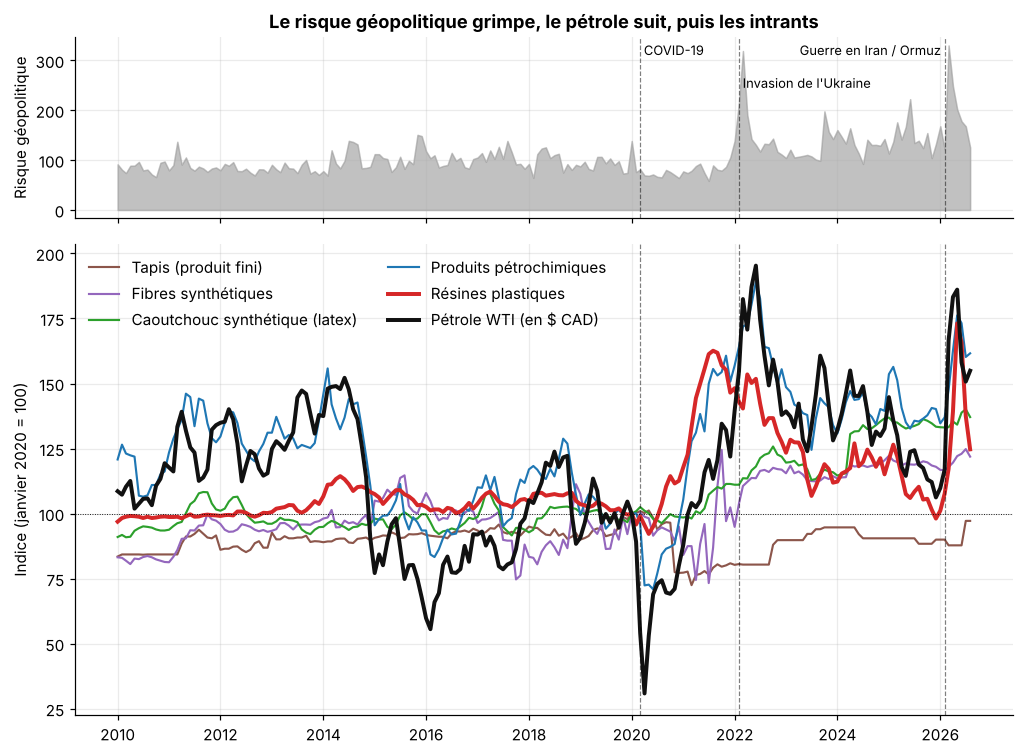

In [5]:
base100 = niveaux[["WTI en CAD", "Petrochimiques", "Resines plastiques",
                   "Caoutchouc synthetique", "Fibres synthetiques", "Tapis"]]
base100 = base100 / base100.loc["2020-01-01"] * 100

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 8), sharex=True,
                               gridspec_kw={"height_ratios": [1, 2.6], "hspace": 0.08})

# Haut : risque géopolitique
ax1.fill_between(data.index, data["Geopolitical risk"], color="#999999", alpha=0.6)
ax1.set_ylabel("Risque géopolitique")
ax1.set_title("Le risque géopolitique grimpe, le pétrole suit, puis les intrants")

# Bas : prix en base 100
for c in ["Tapis", "Fibres synthetiques", "Caoutchouc synthetique", "Petrochimiques", "Resines plastiques", "WTI en CAD"]:
    epais = 2.6 if c in ("WTI en CAD", "Resines plastiques") else 1.4
    ax2.plot(base100.index, base100[c], color=couleurs[c], lw=epais, label=noms[c])
ax2.axhline(100, color="black", lw=0.6, ls=":")
ax2.set_ylabel("Indice (janvier 2020 = 100)")
ax2.legend(loc="upper left", ncol=2, frameon=False)

# Hauteur des étiquettes décalée pour qu'elles ne se chevauchent pas
hauteurs = {"COVID-19": 0.97, "Invasion de l'Ukraine": 0.78, "Guerre en Iran / Ormuz": 0.97}
for nom, date in evenements.items():
    for ax in (ax1, ax2):
        ax.axvline(pd.Timestamp(date), color="black", lw=0.8, ls="--", alpha=0.5)
    derniere = (date == list(evenements.values())[-1])
    ax1.text(pd.Timestamp(date), ax1.get_ylim()[1]*hauteurs[nom], (nom + " ") if derniere else (" " + nom),
             va="top", ha="right" if derniere else "left", fontsize=8.5)

ax2.xaxis.set_major_locator(mdates.YearLocator(2))
ax2.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
fig.savefig("figures/fig1_vue_ensemble.png", bbox_inches="tight")
plt.show()

Deux choses frappent. D'abord, le pétrole (noir) et les produits pétrochimiques (bleu) bougent ensemble. Ensuite, les résines (rouge) ont un comportement à part depuis 2020 : elles montent et descendent par grands blocs, bien plus fort que tout le reste. Les fibres synthétiques (violet) font à peu près ce qu'elles veulent.

## 3. Les résines ont changé de régime en février 2020

### 3.1 Méthode

On cherche des **régimes** : des périodes où une série se comporte différemment (calme, agitée). Pour chaque série, on ajuste un modèle de Markov caché (HMM) sur les variations standardisées. Le nombre d'états (2, 3 ou 4) est choisi par le critère BIC, et les états sont classés **par volatilité croissante** (un classement par moyenne peut étiqueter « stagnant » un état qui est en réalité un état de choc). Cinq points de départ aléatoires évitent de tomber dans un maximum local.

Les règles sont fixées avant de regarder les résultats, et la méthode reprend celle du GWP2.

In [6]:
cols_hmm = ["WTI en CAD", "Resines plastiques", "Fibres synthetiques",
            "Caoutchouc synthetique", "Petrochimiques", "Gaz naturel"]
Z = (X[cols_hmm] - X[cols_hmm].mean()) / X[cols_hmm].std()   # variations standardisées

def trouver_regimes(serie, essais=5):
    "Ajuste un HMM à 2, 3 ou 4 états, garde le meilleur BIC, et classe les états du plus calme au plus agité."
    z = serie.to_numpy().reshape(-1, 1)
    meilleur = None
    for k in (2, 3, 4):
        # on essaie plusieurs départs aléatoires et on garde le meilleur ajustement
        modeles = [GaussianHMM(k, n_iter=300, random_state=r).fit(z) for r in range(essais)]
        m = max(modeles, key=lambda mod: mod.score(z))
        nb_param = k * k + 2 * k - 1
        bic = -2 * m.score(z) + nb_param * np.log(len(z))
        if meilleur is None or bic < meilleur[0]:
            meilleur = (bic, k, m)
    _, k, m = meilleur
    ordre = {ancien: nouveau for nouveau, ancien in enumerate(np.argsort(m.covars_.ravel()))}
    etats = pd.Series(m.predict(z), index=serie.index).map(ordre)
    return etats, k

regimes, nb_etats = {}, {}
for c in cols_hmm:
    regimes[c], nb_etats[c] = trouver_regimes(Z[c])
regimes = pd.DataFrame(regimes)

for c in cols_hmm:
    parts = regimes[c].value_counts(normalize=True).sort_index().round(2).tolist()
    print(f"{noms[c]:34s} états : {nb_etats[c]}   parts du temps : {parts}")

Pétrole WTI (en $ CAD)             états : 2   parts du temps : [0.97, 0.03]
Résines plastiques                 états : 2   parts du temps : [0.6, 0.4]
Fibres synthétiques                états : 2   parts du temps : [0.67, 0.33]
Caoutchouc synthétique (latex)     états : 2   parts du temps : [0.92, 0.08]
Produits pétrochimiques            états : 2   parts du temps : [0.92, 0.08]
Gaz naturel                        états : 2   parts du temps : [0.93, 0.07]


Pour les résines, l'état agité (état 1) n'est pas fait d'épisodes isolés : il forme **un seul bloc continu**. On le vérifie :

In [7]:
agite = regimes["Resines plastiques"] == 1
debut, fin = agite[agite].index.min(), agite[agite].index.max()
continu = agite[debut:fin].all()
print("Régime agité des résines :", debut.strftime("%Y-%m"), "→", fin.strftime("%Y-%m"),
      "| bloc continu :", continu, "|", int(agite.sum()), "mois")

# Et le pétrole ? Combien de mois en état de choc ?
choc_wti = regimes["WTI en CAD"] == 1
print("Mois de choc du pétrole (WTI en CAD) :", int(choc_wti.sum()), "sur", len(choc_wti))
print("   →", [d.strftime("%Y-%m") for d in choc_wti[choc_wti].index])

Régime agité des résines : 2020-02 → 2026-08 | bloc continu : True | 79 mois
Mois de choc du pétrole (WTI en CAD) : 5 sur 199
   → ['2020-03', '2020-04', '2020-05', '2020-06', '2026-03']


Le pétrole n'est en état de choc que **5 mois sur 199** (mars à juin 2020, plus mars 2026). C'est trop peu pour juger du lien pétrole → intrants par les seuls régimes, un seul mois pesant 20 % des cas. C'est pourquoi la suite repose sur l'ensemble des 199 mois, avec des corrélations décalées.

### 3.2 La volatilité des résines, avant et après février 2020

In [8]:
r = X["Resines plastiques"] * 100          # variation mensuelle en %
avant = r[:"2020-01"]
apres = r["2020-02":]

tableau_vol = pd.DataFrame({
    "Mois": [len(avant), len(apres)],
    "Écart-type mensuel (%)": [avant.std(), apres.std()],
    "Variation absolue médiane (%)": [avant.abs().median(), apres.abs().median()],
}, index=["Janv. 2010 – janv. 2020", "Févr. 2020 – août 2026"]).round(2)
display(tableau_vol)

facteur = apres.std() / avant.std()
print(f"La volatilité mensuelle des résines a été multipliée par {facteur:.1f}.")

resultats["volatilite_resines"] = {
    "ecart_type_avant": round(avant.std(), 2), "ecart_type_apres": round(apres.std(), 2),
    "mediane_abs_avant": round(avant.abs().median(), 2), "mediane_abs_apres": round(apres.abs().median(), 2),
    "facteur": round(facteur, 1), "mois_agites": int(agite.sum()),
}

,Mois,Écart-type mensuel (%),Variation absolue médiane (%)
Janv. 2010 – janv. 2020,120,1.18,0.74
Févr. 2020 – août 2026,79,5.74,3.60


La volatilité mensuelle des résines a été multipliée par 4.8.


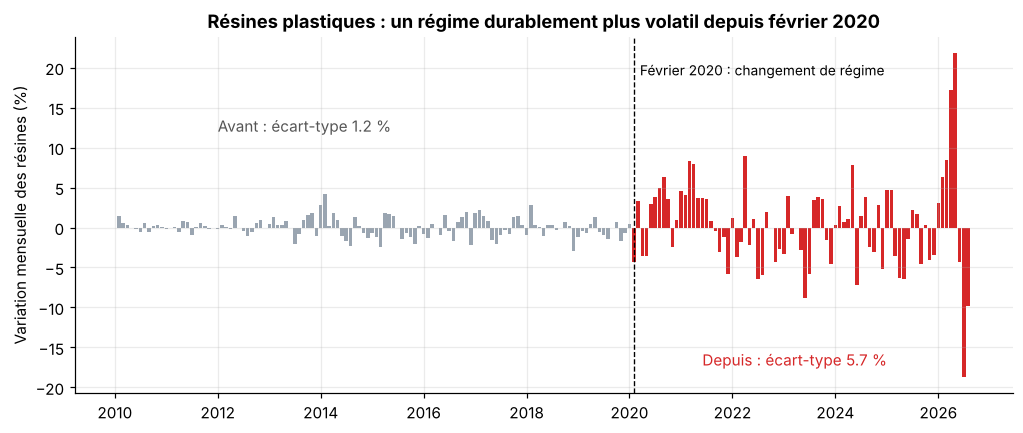

In [9]:
fig, ax = plt.subplots(figsize=(11, 4.2))
couleur_barres = np.where(agite, "#d62728", "#9aa5b1")
ax.bar(r.index, r, width=25, color=couleur_barres)
ax.axvline(pd.Timestamp("2020-02-01"), color="black", ls="--", lw=0.9)
ax.text(pd.Timestamp("2020-03-15"), r.max()*0.95, "Février 2020 : changement de régime", fontsize=9, va="top")
ax.text(pd.Timestamp("2012-01-01"), r.max()*0.55, f"Avant : écart-type {avant.std():.1f} %", fontsize=10, color="#555555")
ax.text(pd.Timestamp("2021-06-01"), r.min()*0.95, f"Depuis : écart-type {apres.std():.1f} %", fontsize=10, color="#d62728", va="bottom")
ax.set_ylabel("Variation mensuelle des résines (%)")
ax.set_title("Résines plastiques : un régime durablement plus volatil depuis février 2020")
fig.savefig("figures/fig2_volatilite_resines.png", bbox_inches="tight")
plt.show()

La variation mensuelle des résines est passée d'environ 1 % à près de 6 % (écart-type). Même lue par la médiane des variations absolues, moins sensible aux mois extrêmes, le saut est réel : de 0,7 % à 3,6 %. Ce n'est donc pas l'effet de deux ou trois mois spectaculaires. Pour un acheteur, un prix qui varie de 3 à 4 % **dans un mois ordinaire** change la façon de budgéter et de négocier.

La cause n'est pas établie ici : pandémie, goulots d'étranglement logistiques, gel du Texas de 2021, guerre en Ukraine, puis conflit au Moyen-Orient se sont succédé. Le carnet constate le changement, il ne l'explique pas.

## 4. Le pétrole annonce-t-il les intrants ? Les décalages

### 4.1 Corrélations décalées

Pour chaque intrant, on mesure la corrélation entre sa variation mensuelle et celle du WTI en dollars canadiens observée **L mois plus tôt** (L de 0 à 6). Avec environ 198 observations, une corrélation n'est distinguable du hasard qu'au-delà de **0,14** en valeur absolue (seuil 1,96 / √n).

In [10]:
entrees = ["Petrochimiques", "Resines plastiques", "Caoutchouc synthetique", "Fibres synthetiques", "Gaz naturel"]

def correlations_decalees(P, entree, max_retard=6):
    "Corrélation entre la variation de l'intrant et celle du pétrole L mois plus tôt."
    return [P[entree].corr(P["WTI en CAD"].shift(L)) for L in range(max_retard + 1)]

corr_totale = pd.DataFrame({noms[c]: correlations_decalees(X, c) for c in entrees},
                           index=[f"{L} mois" for L in range(7)]).T
seuil = 1.96 / np.sqrt(len(X))
print(f"Seuil de signification : ±{seuil:.2f}")
display(corr_totale.round(2))

# On garde le décalage où la corrélation est la plus forte pour chaque intrant
meilleur_retard = {c: int(np.argmax(correlations_decalees(X, c))) for c in entrees}
resultats["correlations_totales"] = {c: [round(v, 2) for v in correlations_decalees(X, c)] for c in entrees}
resultats["meilleur_retard"] = meilleur_retard
print("Décalage de corrélation maximale (mois) :", {noms[k]: v for k, v in meilleur_retard.items()})

Seuil de signification : ±0.14


,0 mois,1 mois,2 mois,3 mois,4 mois,5 mois,6 mois
Produits pétrochimiques,0.46,0.50,0.23,-0.00,-0.14,-0.04,-0.02
Résines plastiques,0.16,0.43,0.24,0.04,-0.11,-0.24,-0.11
Caoutchouc synthétique (latex),-0.08,0.10,0.23,0.16,0.15,0.03,-0.00
Fibres synthétiques,-0.09,-0.06,0.13,0.06,0.03,-0.05,0.02
Gaz naturel,0.05,0.00,0.20,0.10,-0.07,-0.02,0.05


Décalage de corrélation maximale (mois) : {'Produits pétrochimiques': 1, 'Résines plastiques': 1, 'Caoutchouc synthétique (latex)': 2, 'Fibres synthétiques': 2, 'Gaz naturel': 2}


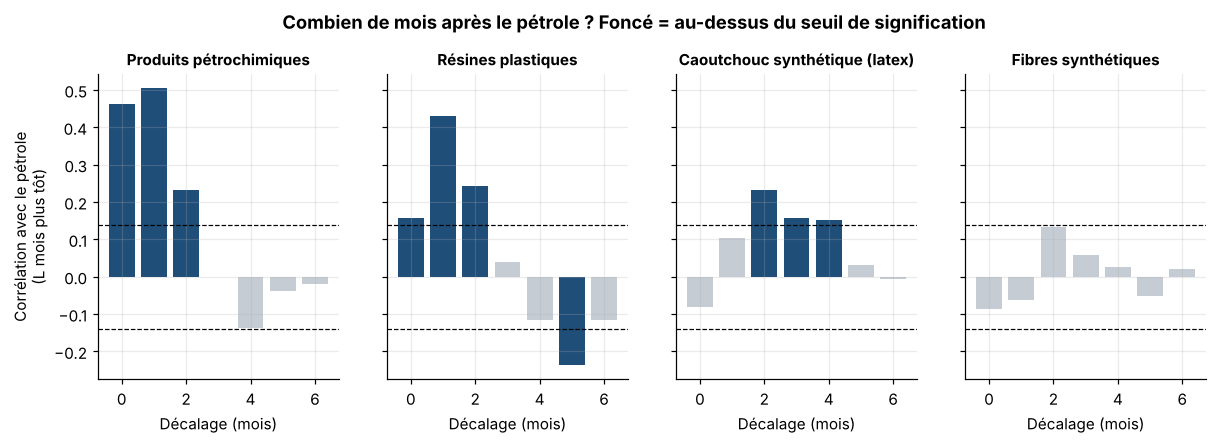

In [11]:
fig, axes = plt.subplots(1, 4, figsize=(13, 3.6), sharey=True)
for ax, c in zip(axes, ["Petrochimiques", "Resines plastiques", "Caoutchouc synthetique", "Fibres synthetiques"]):
    vals = correlations_decalees(X, c)
    barres = ["#1f4e79" if abs(v) > seuil else "#c5ccd3" for v in vals]
    ax.bar(range(7), vals, color=barres)
    ax.axhline(seuil, color="black", ls="--", lw=0.8); ax.axhline(-seuil, color="black", ls="--", lw=0.8)
    ax.set_title(noms[c], fontsize=10)
    ax.set_xlabel("Décalage (mois)")
axes[0].set_ylabel("Corrélation avec le pétrole\n(L mois plus tôt)")
fig.suptitle("Combien de mois après le pétrole ? Foncé = au-dessus du seuil de signification", y=1.04, fontweight="bold")
fig.savefig("figures/fig3_decalages.png", bbox_inches="tight")
plt.show()

**Lecture**

* **Produits pétrochimiques** : lien fort dès le même mois (0,46) et maximal à **1 mois** (0,50), qui s'éteint ensuite.
* **Résines plastiques** : le pétrole se répercute surtout après **1 mois** (0,43), avec un prolongement à 2 mois (0,24).
* **Caoutchouc synthétique** : réaction plus lente et plus faible, maximale à **2 mois** (0,23), encore positive jusqu'à 4 mois.
* **Fibres synthétiques et gaz naturel** : aucun lien net. Les corrélations restent proches du seuil.

On ne commente pas les corrélations isolées à des décalages éloignés : sur 35 calculs, environ deux dépasseront le seuil par simple hasard.

### 4.2 Le lien est-il stable dans le temps ?

La pandémie et l'inflation de 2021 à 2022 ont tout secoué. Pour savoir si les décalages tiennent, on refait le calcul sur trois périodes : avant 2020, depuis 2020, et depuis 2021 (qui écarte les mois de pandémie). Le seuil est recalculé pour chaque période.

In [12]:
periodes = {
    "Avant 2020":  X[:"2019-12"],
    "Depuis 2020": X["2020-01":],
    "Depuis 2021": X["2021-01":],
}
lignes = []
for nom_periode, P in periodes.items():
    for c in ["Petrochimiques", "Resines plastiques", "Caoutchouc synthetique", "Fibres synthetiques"]:
        v = correlations_decalees(P, c, max_retard=4)
        lignes.append({"Période": nom_periode, "Mois": len(P), "Seuil": round(1.96/np.sqrt(len(P)), 2),
                       "Intrant": noms[c], **{f"{L} mois": round(x, 2) for L, x in enumerate(v)}})
robustesse = pd.DataFrame(lignes)
display(robustesse.set_index(["Période", "Intrant"]))
resultats["robustesse"] = robustesse.to_dict(orient="records")

Mois  Seuil  0 mois  1 mois  \
Période     Intrant                                                       
Avant 2020  Produits pétrochimiques          119   0.18    0.38    0.50   
            Résines plastiques               119   0.18    0.13    0.31   
            Caoutchouc synthétique (latex)   119   0.18   -0.17    0.10   
            Fibres synthétiques              119   0.18   -0.28   -0.04   
Depuis 2020 Produits pétrochimiques           80   0.22    0.53    0.53   
            Résines plastiques                80   0.22    0.17    0.48   
            Caoutchouc synthétique (latex)    80   0.22   -0.03    0.10   
            Fibres synthétiques               80   0.22    0.01   -0.08   
Depuis 2021 Produits pétrochimiques           68   0.24    0.50    0.59   
            Résines plastiques                68   0.24    0.32    0.66   
            Caoutchouc synthétique (latex)    68   0.24    0.08    0.21   
            Fibres synthétiques               68   0.24    0.08   -0.06   

                                            2 mois  3 mois  4 mois  
Période     Intrant                                                 
Avant 2020  Produits pétrochimiques           0.12   -0.02   -0.08  
            Résines plastiques                0.23    0.20   -0.03  
            Caoutchouc synthétique (latex)    0.27    0.19    0.16  
            Fibres synthétiques               0.19   -0.04    0.08  
Depuis 2020 Produits pétrochimiques           0.31    0.01   -0.20  
            Résines plastiques                0.26    0.02   -0.14  
            Caoutchouc synthétique (latex)    0.21    0.15    0.15  
            Fibres synthétiques               0.10    0.12   -0.01  
Depuis 2021 Produits pétrochimiques           0.24   -0.14   -0.10  
            Résines plastiques                0.34   -0.04   -0.27  
            Caoutchouc synthétique (latex)    0.25    0.12   -0.00  
            Fibres synthétiques               0.02    0.15    0.05

**Lecture de la robustesse**

* **Pétrochimiques** : le pic est à 1 mois dans les trois périodes (0,50, 0,53 et 0,59). Solide.
* **Résines** : le décalage d'un mois est constant, mais **le lien se resserre nettement** : 0,31, puis 0,48, puis 0,66. Avant 2020, l'effet du pétrole s'étalait sur plusieurs mois. Depuis, il se concentre sur un à deux mois. La transmission est plus forte et plus rapide.
* **Caoutchouc synthétique** : le pic reste à 2 mois (0,27, 0,21, 0,25), mais son amplitude frôle le seuil. À retenir comme **lien modéré, à confirmer**.
* **Fibres synthétiques** : rien de stable. La corrélation négative d'avant 2020 au décalage zéro disparaît ensuite et n'a pas d'interprétation économique.

**Une précaution importante.** La période « depuis 2021 » contient l'épisode de 2026 lui-même. Le resserrement des résines vient-il uniquement de là ? On refait le calcul en s'arrêtant en décembre 2025.

In [13]:
P_sans_2026 = X["2021-01":"2025-12"]
print(f"2021 à décembre 2025 : {len(P_sans_2026)} mois, seuil de signification ±{1.96/np.sqrt(len(P_sans_2026)):.2f}")
sans_2026 = {c: [float(round(v, 2)) for v in correlations_decalees(P_sans_2026, c, max_retard=3)] for c in ["Petrochimiques", "Resines plastiques"]}
for c, v in sans_2026.items():
    print(f"  {noms[c]:28s} décalages 0 à 3 mois : {v}")
resultats["correlations_2021_2025"] = sans_2026

2021 à décembre 2025 : 60 mois, seuil de signification ±0.25
  Produits pétrochimiques      décalages 0 à 3 mois : [0.49, 0.52, 0.18, -0.13]
  Résines plastiques           décalages 0 à 3 mois : [0.23, 0.56, 0.1, 0.07]


Sans 2026, le lien des résines à 1 mois reste à **0,56** (contre 0,31 avant 2020). Le resserrement est donc réel et antérieur à la guerre en Iran ; l'épisode de 2026 le pousse ensuite à 0,66. On peut le dire sans exagérer : le lien a été multiplié par près de deux avant 2026, et la guerre l'a confirmé.

Même chose en continu : voici la corrélation à 1 mois sur une fenêtre glissante de 36 mois.

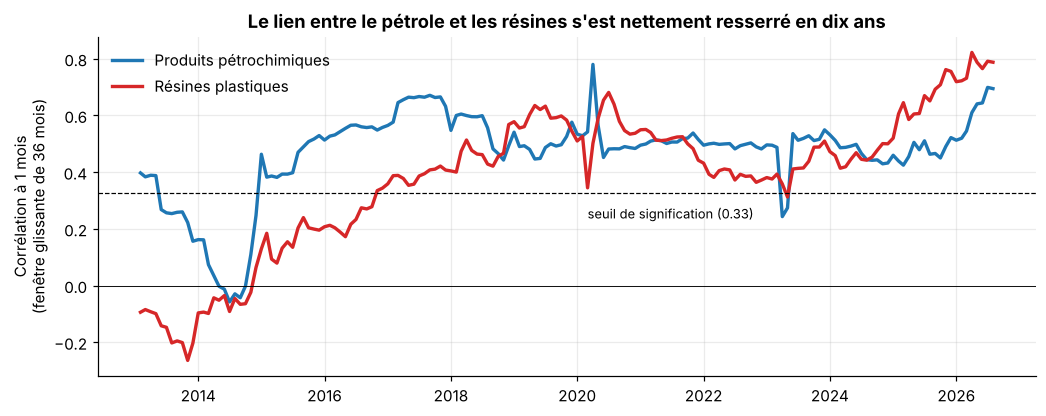

{'Petrochimiques': np.float64(0.69), 'Resines plastiques': np.float64(0.79)}


In [14]:
fenetre = 36
glissante = pd.DataFrame({
    c: X[c].rolling(fenetre).corr(X["WTI en CAD"].shift(1)) for c in ["Petrochimiques", "Resines plastiques"]
}).dropna()

fig, ax = plt.subplots(figsize=(11, 4))
for c in glissante.columns:
    ax.plot(glissante.index, glissante[c], color=couleurs[c], lw=2.2, label=noms[c])
seuil36 = 1.96 / np.sqrt(fenetre)
ax.axhline(seuil36, color="black", ls="--", lw=0.8)
ax.text(glissante.index[85], seuil36 - 0.09, f"seuil de signification ({seuil36:.2f})", fontsize=8.5)
ax.axhline(0, color="black", lw=0.6)
ax.set_ylabel("Corrélation à 1 mois\n(fenêtre glissante de 36 mois)")
ax.set_title("Le lien entre le pétrole et les résines s'est nettement resserré en dix ans")
ax.legend(frameon=False, loc="upper left")
fig.savefig("figures/fig4_correlation_glissante.png", bbox_inches="tight")
plt.show()

resultats["glissante_fin"] = {c: round(glissante[c].iloc[-1], 2) for c in glissante.columns}
resultats["glissante_debut_resines"] = round(glissante["Resines plastiques"].iloc[0], 2)
print(resultats["glissante_fin"])

### 4.3 Un test plus exigeant : la précédence de Granger

Une corrélation décalée peut venir d'un hasard de calendrier. Le test de Granger pose une question plus précise : **connaître le pétrole des derniers mois aide-t-il à prévoir l'intrant mieux que son propre passé seul ?** Une valeur p sous 0,05 dit que oui.

Attention au vocabulaire : « précède et aide à prévoir » n'est pas « cause ». C'est un test de précédence statistique.

In [15]:
def test_granger(P, intrant, retards=3):
    "p-valeurs du test de Granger : le pétrole aide-t-il à prévoir l'intrant ?"
    with contextlib.redirect_stdout(io.StringIO()):          # on fait taire les impressions de statsmodels
        res = grangercausalitytests(P[[intrant, "WTI en CAD"]], maxlag=retards)
    return {f"{k} mois": res[k][0]["ssr_ftest"][1] for k in res}

lignes = []
for nom_periode, P in {"Toute la période": X, "Depuis 2021": X["2021-01":]}.items():
    for c in ["Petrochimiques", "Resines plastiques", "Caoutchouc synthetique", "Fibres synthetiques"]:
        lignes.append({"Période": nom_periode, "Intrant": noms[c], **test_granger(P, c)})
granger = pd.DataFrame(lignes).set_index(["Période", "Intrant"])
display(granger.round(3))
resultats["granger"] = granger.round(4).reset_index().to_dict(orient="records")

1 mois  2 mois  3 mois
Période          Intrant                                               
Toute la période Produits pétrochimiques          0.000   0.000   0.000
                 Résines plastiques               0.000   0.000   0.000
                 Caoutchouc synthétique (latex)   0.062   0.006   0.024
                 Fibres synthétiques              0.255   0.123   0.202
Depuis 2021      Produits pétrochimiques          0.000   0.000   0.000
                 Résines plastiques               0.000   0.000   0.000
                 Caoutchouc synthétique (latex)   0.093   0.068   0.083
                 Fibres synthétiques              0.691   0.906   0.645

Pour les **produits pétrochimiques** et les **résines**, la valeur p est pratiquement nulle : le pétrole précède bel et bien ces deux intrants, sur toute la période comme depuis 2021. Pour le **caoutchouc synthétique**, le signal est présent mais plus faible (autour de 0,01 à 0,06 sur toute la période, plus fragile depuis 2021). Pour les **fibres synthétiques**, rien : p entre 0,12 et 0,91. Cela confirme le résultat des corrélations par une méthode différente.

## 5. Combien un mois de pétrole fait-il bouger l'intrant ? Les élasticités

Les corrélations disent *si* et *quand*. L'acheteur veut aussi savoir *de combien*. On estime pour chaque intrant l'effet de la variation du pétrole du même mois et des trois mois précédents (régression à retards distribués, erreurs robustes). Comme les variations sont en logarithme, un coefficient de 0,20 se lit : « une hausse de 10 % du pétrole s'accompagne d'une hausse d'environ 2 % de l'intrant ».

In [16]:
def retards_distribues(P, intrant, nb_retards=3):
    "Régression de la variation de l'intrant sur celle du pétrole (mois courant + retards)."
    petrole = pd.concat({f"L{l}": P["WTI en CAD"].shift(l) for l in range(nb_retards + 1)}, axis=1)
    df = pd.concat([P[intrant].rename("y"), petrole], axis=1).dropna()
    return sm.OLS(df["y"], sm.add_constant(df.drop(columns="y"))).fit(cov_type="HAC", cov_kwds={"maxlags": 3})

lignes = []
for nom_periode, P in {"Toute la période": X, "Depuis 2021": X["2021-01":]}.items():
    for c in ["Petrochimiques", "Resines plastiques", "Caoutchouc synthetique", "Fibres synthetiques"]:
        m = retards_distribues(P, c)
        coefs = m.params[["L0", "L1", "L2", "L3"]]
        lignes.append({
            "Période": nom_periode, "Intrant": noms[c],
            "même mois": coefs["L0"], "1 mois": coefs["L1"], "2 mois": coefs["L2"], "3 mois": coefs["L3"],
            "Effet cumulé": coefs.sum(), "R²": m.rsquared,
        })
elasticites = pd.DataFrame(lignes).set_index(["Période", "Intrant"])
display(elasticites.round(3))

# Traduction concrète : +10 % de pétrole = combien sur l'intrant, en cumulé sur 4 mois ?
elasticites["+10 % de pétrole → intrant (%)"] = (elasticites["Effet cumulé"] * 10).round(1)
display(elasticites[["Effet cumulé", "+10 % de pétrole → intrant (%)", "R²"]].round(2))
resultats["elasticites"] = elasticites.round(3).reset_index().to_dict(orient="records")

même mois  1 mois  2 mois  \
Période          Intrant                                                     
Toute la période Produits pétrochimiques             0.225   0.199   0.099   
                 Résines plastiques                  0.042   0.141   0.056   
                 Caoutchouc synthétique (latex)     -0.009   0.017   0.032   
                 Fibres synthétiques                -0.022  -0.047   0.079   
Depuis 2021      Produits pétrochimiques             0.215   0.251   0.101   
                 Résines plastiques                  0.146   0.396   0.151   
                 Caoutchouc synthétique (latex)      0.026   0.043   0.050   
                 Fibres synthétiques                 0.140  -0.084   0.021   

                                                 3 mois  Effet cumulé     R²  
Période          Intrant                                                      
Toute la période Produits pétrochimiques          0.057         0.580  0.435  
                 Résines plastiques               0.034         0.273  0.224  
                 Caoutchouc synthétique (latex)   0.023         0.063  0.073  
                 Fibres synthétiques              0.001         0.010  0.028  
Depuis 2021      Produits pétrochimiques         -0.030         0.538  0.472  
                 Résines plastiques               0.012         0.705  0.482  
                 Caoutchouc synthétique (latex)   0.028         0.147  0.116  
                 Fibres synthétiques              0.144         0.221  0.048

Effet cumulé  \
Période          Intrant                                        
Toute la période Produits pétrochimiques                 0.58   
                 Résines plastiques                      0.27   
                 Caoutchouc synthétique (latex)          0.06   
                 Fibres synthétiques                     0.01   
Depuis 2021      Produits pétrochimiques                 0.54   
                 Résines plastiques                      0.70   
                 Caoutchouc synthétique (latex)          0.15   
                 Fibres synthétiques                     0.22   

                                                 +10 % de pétrole → intrant (%)  \
Période          Intrant                                                          
Toute la période Produits pétrochimiques                                    5.8   
                 Résines plastiques                                         2.7   
                 Caoutchouc synthétique (latex)                             0.6   
                 Fibres synthétiques                                        0.1   
Depuis 2021      Produits pétrochimiques                                    5.4   
                 Résines plastiques                                         7.0   
                 Caoutchouc synthétique (latex)                             1.5   
                 Fibres synthétiques                                        2.2   

                                                   R²  
Période          Intrant                               
Toute la période Produits pétrochimiques         0.43  
                 Résines plastiques              0.22  
                 Caoutchouc synthétique (latex)  0.07  
                 Fibres synthétiques             0.03  
Depuis 2021      Produits pétrochimiques         0.47  
                 Résines plastiques              0.48  
                 Caoutchouc synthétique (latex)  0.12  
                 Fibres synthétiques             0.05

**Lecture.** Pour les pétrochimiques, une hausse de 10 % du pétrole s'accompagne d'environ **+6 %** sur les quatre mois qui suivent (l'effet est réparti entre le même mois et les deux suivants). Pour les résines, l'effet moyen sur toute la période est plus modeste (≈ +3 %), mais **il est nettement plus élevé depuis 2021**, particulièrement à un mois. Attention : ce chiffre de 2021 (≈ +7 %) inclut l'épisode de 2026. Estimé en s'arrêtant en décembre 2025, l'effet cumulé des résines est d'environ +4 % : plus que l'historique complet, mais bien moins que ce que 2026 a produit. Pour les fibres, les coefficients ne veulent rien dire : le pétrole n'explique presque rien (R² voisin de zéro).

Le pétrole explique une part croissante des variations des résines (R² de 0,22 sur toute la période, 0,48 depuis 2021), mais environ la moitié reste due à d'autres forces. La section suivante le rend très concret.

## 6. Grandeur nature : l'épisode de 2026

Le 28 février 2026, les États-Unis et Israël ont frappé l'Iran. Le détroit d'Ormuz a été perturbé, le baril a franchi les 100 $ US fin mars pour la première fois depuis 2022 et le WTI a connu en mars l'une de ses plus fortes hausses mensuelles de l'histoire récente. Un cessez-le-feu et un accord ont ensuite fait redescendre les prix au printemps et à l'été. C'est exactement le genre de choc que l'article cherche à éclairer, et il se trouve dans nos données.

On compare deux épisodes avec la même méthode : **février 2022** (invasion de l'Ukraine) et **février 2026** (guerre en Iran). Pour chacun, on ramène tout à 100 au mois du déclenchement.

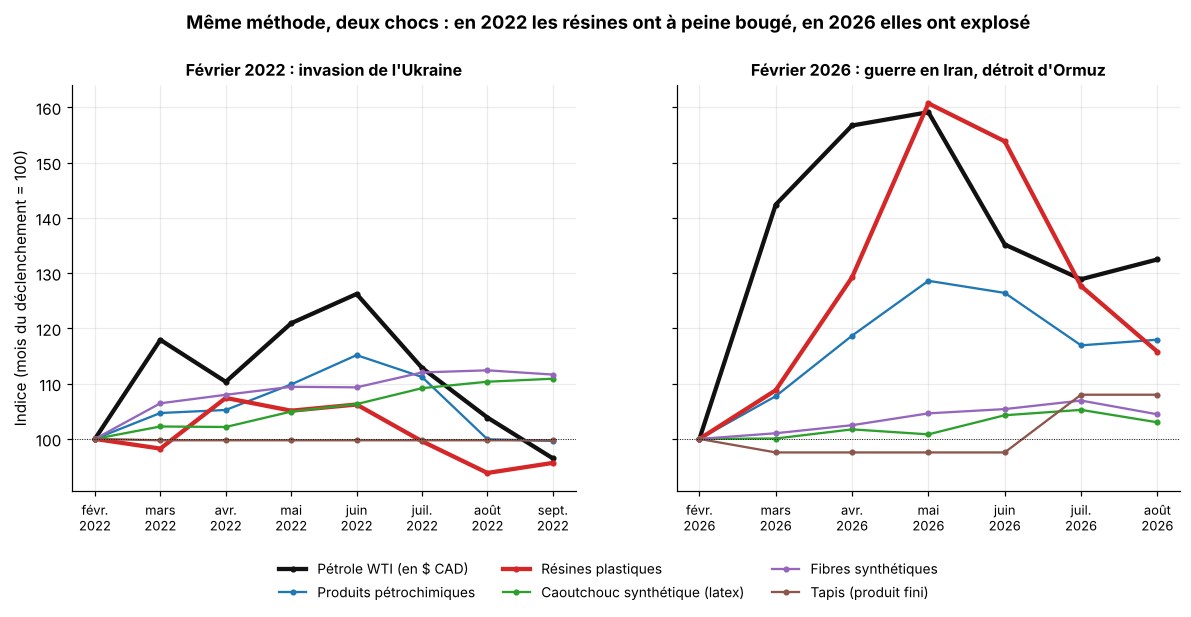

In [17]:
def epoque(debut, fin):
    "Niveaux ramenés à 100 le mois du déclenchement."
    morceau = niveaux.loc[debut:fin, ["WTI en CAD", "Petrochimiques", "Resines plastiques",
                                      "Caoutchouc synthetique", "Fibres synthetiques", "Tapis"]]
    return morceau / morceau.iloc[0] * 100

ep22 = epoque("2022-02-01", "2022-09-01")
ep26 = epoque("2026-02-01", "2026-08-01")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
for ax, ep, titre in [(axes[0], ep22, "Février 2022 : invasion de l'Ukraine"),
                      (axes[1], ep26, "Février 2026 : guerre en Iran, détroit d'Ormuz")]:
    for c in ep.columns:
        epais = 2.8 if c in ("WTI en CAD", "Resines plastiques") else 1.5
        ax.plot(range(len(ep)), ep[c], color=couleurs[c], lw=epais, marker="o", ms=3, label=noms[c])
    ax.axhline(100, color="black", lw=0.6, ls=":")
    ax.set_xticks(range(len(ep)))
    ax.set_xticklabels([mois_fr(d, True) for d in ep.index], fontsize=8.5)
    ax.set_title(titre, fontsize=10.5)
axes[0].set_ylabel("Indice (mois du déclenchement = 100)")
handles, labels = axes[1].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=3, frameon=False, fontsize=9, bbox_to_anchor=(0.5, -0.12))
fig.suptitle("Même méthode, deux chocs : en 2022 les résines ont à peine bougé, en 2026 elles ont explosé",
             y=1.02, fontweight="bold")
fig.savefig("figures/fig5_episodes_2022_2026.png", bbox_inches="tight")
plt.show()

In [18]:
def resume_episode(ep, nom):
    sommet = ep.idxmax()
    hausse = (ep.max() - 100).round(0)
    mois_apres = [(sommet[c].year - ep.index[0].year) * 12 + sommet[c].month - ep.index[0].month for c in ep.columns]
    out = pd.DataFrame({"Hausse max. (%)": hausse, "Sommet": sommet.map(lambda d: d.strftime("%Y-%m")),
                        "Mois après le déclenchement": mois_apres})
    out.index = [noms[c] for c in out.index]
    out.insert(0, "Épisode", nom)
    return out

tab_episodes = pd.concat([resume_episode(ep22, "2022"), resume_episode(ep26, "2026")])
display(tab_episodes)
resultats["episodes"] = tab_episodes.reset_index().rename(columns={"index": "Série"}).to_dict(orient="records")

,Épisode,Hausse max. (%),Sommet,Mois après le déclenchement
Pétrole WTI (en $ CAD),2022,26.0,2022-06,4
Produits pétrochimiques,2022,15.0,2022-06,4
Résines plastiques,2022,7.0,2022-04,2
Caoutchouc synthétique (latex),2022,11.0,2022-09,7
Fibres synthétiques,2022,12.0,2022-08,6
Tapis (produit fini),2022,0.0,2022-02,0
Pétrole WTI (en $ CAD),2026,59.0,2026-05,3
Produits pétrochimiques,2026,29.0,2026-05,3
Résines plastiques,2026,61.0,2026-05,3
Caoutchouc synthétique (latex),2026,5.0,2026-07,5


In [19]:
# Les chiffres qu'on citera dans l'article : variations de février à mai 2026, puis jusqu'en août 2026
variation = (ep26 - 100).round(0)
display(variation.rename(columns=noms).astype(int))

resultats["episode_2026"] = {
    "variation_par_mois": {d.strftime("%Y-%m"): {c: float(variation.loc[d, c]) for c in variation.columns} for d in variation.index},
    "wti_usd": {d.strftime("%Y-%m"): round(float(data.loc[d, "WTI spot"]), 1) for d in ep26.index},
    "risque_geopolitique_mars_2026": round(float(data.loc["2026-03-01", "Geopolitical risk"]), 0),
    "risque_geopolitique_mars_2022": round(float(data.loc["2022-03-01", "Geopolitical risk"]), 0),
}

,Pétrole WTI (en $ CAD),Produits pétrochimiques,Résines plastiques,Caoutchouc synthétique (latex),Fibres synthétiques,Tapis (produit fini)
DATE,,,,,,
2026-02-01,0,0,0,0,0,0
2026-03-01,42,8,9,0,1,-2
2026-04-01,57,19,29,2,2,-2
2026-05-01,59,29,61,1,5,-2
2026-06-01,35,26,54,4,5,-2
2026-07-01,29,17,28,5,7,8
2026-08-01,32,18,16,3,4,8


**Ce que montre l'épisode de 2026**

* Le pétrole en dollars canadiens bondit de **+42 % dès mars** et atteint **+59 % en mai**.
* Les produits pétrochimiques suivent avec un temps de retard : +8 % en mars, +19 % en avril, **+29 % en mai**.
* Les résines plastiques ont mis **un à deux mois à réagir** : +9 % en mars, alors que le pétrole faisait déjà +42 %, puis +29 % en avril et **+61 % en mai**, le sommet. Elles ont rattrapé et même dépassé le pétrole, puis ont reculé aussi vite (+28 % en juillet, +16 % en août).
* Le caoutchouc synthétique (+1 à +5 %) et les fibres synthétiques (+1 à +7 %) n'ont presque pas bougé.
* L'indice du **produit fini** (tapis) est resté à **-2 %** jusqu'en juin, et n'a rebondi qu'en juillet (+8 %). Le coût des matières a donc grimpé plusieurs mois avant que le prix de vente de l'industrie suive : c'est l'effet de ciseaux qui inquiète une direction.

**Et 2022 ?** Avec la même méthode, le pétrole en dollars canadiens a pris +26 % au plus haut (juin 2022) et les produits pétrochimiques +15 %. Les résines, elles, n'ont gagné que +7 % au mieux (en avril) avant de reculer, et les fibres synthétiques (+12 %) comme le caoutchouc (+11 %) ont monté lentement, sans lien clair avec le pétrole. Chaque choc a donc sa signature : l'ampleur de la transmission dépend de l'état de l'offre au moment où il arrive. C'est une raison de plus de lire chaque intrant séparément.

## 7. Le test qui compte : prédire 2026 sans l'avoir vu

Une corrélation estimée sur tout l'échantillon, y compris l'épisode qu'on veut expliquer, est un peu trop flatteuse. On fait donc un test plus honnête : on **estime la relation avec les données jusqu'en décembre 2025 seulement**, on lui donne le pétrole réel de 2026 et on regarde ce qu'elle prévoit pour les intrants, sans jamais lui montrer leurs vrais prix de 2026.

In [20]:
def prevoir_2026(intrant, debut_entrainement=None, nb_retards=2):
    "Estime sur les données jusqu'en déc. 2025, puis prévoit les variations de 2026 à partir du pétrole réel."
    entrainement = X[:"2025-12"] if debut_entrainement is None else X[debut_entrainement:"2025-12"]
    m = retards_distribues(entrainement, intrant, nb_retards)
    petrole = pd.concat({f"L{l}": X["WTI en CAD"].shift(l) for l in range(nb_retards + 1)}, axis=1).loc["2026-01":]
    prevu = m.predict(sm.add_constant(petrole, has_constant="add"))
    return pd.DataFrame({"observé": X.loc["2026-01":, intrant], "prévu": prevu})

oos = {
    "Petrochimiques": prevoir_2026("Petrochimiques"),
    "Resines (estimé 2010-2025)": prevoir_2026("Resines plastiques"),
    "Resines (estimé 2021-2025)": prevoir_2026("Resines plastiques", "2021-01"),
}

lignes = []
for nom, df in oos.items():
    mars_juin = df.loc["2026-03":"2026-06"]
    lignes.append({
        "Modèle": nom,
        "Corrélation prévu/observé (janv.–août)": df.corr().iloc[0, 1],
        "Hausse cumulée observée, mars–juin (%)": (np.exp(mars_juin["observé"].sum()) - 1) * 100,
        "Hausse cumulée prévue, mars–juin (%)": (np.exp(mars_juin["prévu"].sum()) - 1) * 100,
    })
tab_oos = pd.DataFrame(lignes).set_index("Modèle")
display(tab_oos.round(2))
resultats["hors_echantillon"] = tab_oos.round(2).reset_index().to_dict(orient="records")

,Corrélation prévu/observé (janv.–août),"Hausse cumulée observée, mars–juin (%)","Hausse cumulée prévue, mars–juin (%)"
Modèle,,,
Petrochimiques,0.92,26.42,25.68
Resines (estimé 2010-2025),0.86,53.85,7.18
Resines (estimé 2021-2025),0.81,53.85,18.15


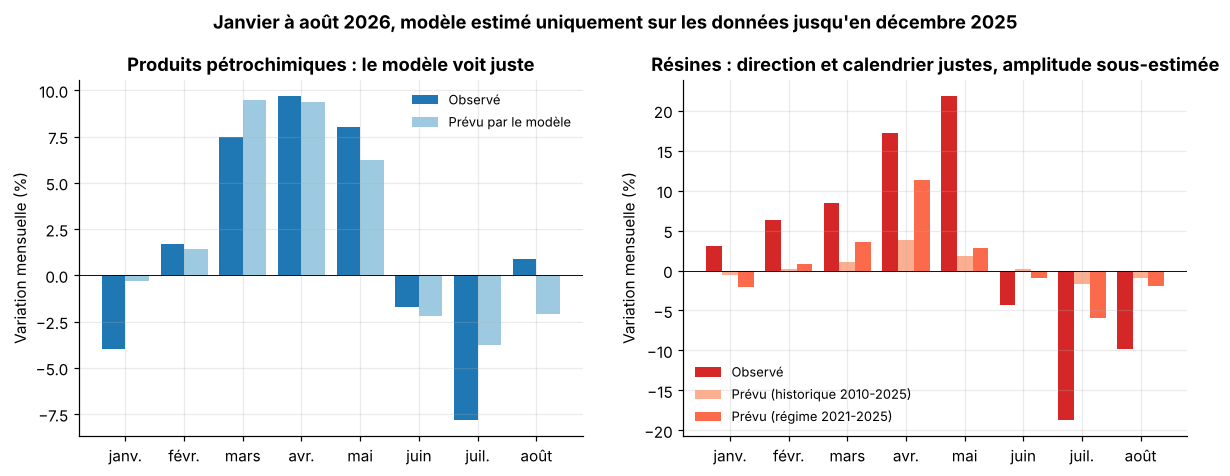

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
mois = oos["Petrochimiques"].index
x = np.arange(len(mois))

ax = axes[0]
ax.bar(x - 0.2, oos["Petrochimiques"]["observé"] * 100, 0.4, color=couleurs["Petrochimiques"], label="Observé")
ax.bar(x + 0.2, oos["Petrochimiques"]["prévu"] * 100, 0.4, color="#9ecae1", label="Prévu par le modèle")
ax.set_title("Produits pétrochimiques : le modèle voit juste")

ax = axes[1]
ax.bar(x - 0.27, oos["Resines (estimé 2010-2025)"]["observé"] * 100, 0.27, color=couleurs["Resines plastiques"], label="Observé")
ax.bar(x, oos["Resines (estimé 2010-2025)"]["prévu"] * 100, 0.27, color="#fcae91", label="Prévu (historique 2010-2025)")
ax.bar(x + 0.27, oos["Resines (estimé 2021-2025)"]["prévu"] * 100, 0.27, color="#fb6a4a", label="Prévu (régime 2021-2025)")
ax.set_title("Résines : direction et calendrier justes, amplitude sous-estimée")

for ax in axes:
    ax.axhline(0, color="black", lw=0.6)
    ax.set_xticks(x); ax.set_xticklabels([mois_fr(d) for d in mois])
    ax.set_ylabel("Variation mensuelle (%)")
    ax.legend(frameon=False, fontsize=8.5)
fig.suptitle("Janvier à août 2026, modèle estimé uniquement sur les données jusqu'en décembre 2025", y=1.03, fontweight="bold")
fig.savefig("figures/fig6_hors_echantillon.png", bbox_inches="tight")
plt.show()

**Résultats**

* **Produits pétrochimiques** : le modèle, qui n'a jamais vu 2026, prévoit une hausse cumulée de mars à juin très proche de ce qui s'est passé (+25,7 % prévu contre +26,4 % observé) et suit les mois de près (corrélation 0,92). Le signal pétrole fonctionne.
* **Résines plastiques** : le modèle prévoit **la bonne direction et le bon calendrier** (corrélation 0,86 : les résines montent d'avril à mai, redescendent en juillet), mais **sous-estime beaucoup l'amplitude**. L'historique complet suggère +7 % de mars à juin, le régime 2021-2025 suggère +18 %, alors que la hausse réelle a été de **+54 %**.

C'est le message central pour un acheteur : *le pétrole dit dans quelle direction et à peu près quand. Il ne dit pas combien, parce que la résine amplifie le signal depuis 2020.* Le scénario du pire doit être bâti avec la volatilité des résines, pas avec la sensibilité moyenne historique.

## 8. Un signal d'alerte simple pour la fonction achats

Pour passer de l'analyse à une règle utilisable, on pose une question concrète : **quand le pétrole en dollars canadiens monte de plus de 10 % en un mois, que se passe-t-il pour chaque intrant dans les deux mois suivants ?** On compare à la fréquence normale (tous les mois, sans condition) pour ne pas se laisser tromper par la tendance générale.

In [22]:
def regle_alerte(seuil_hausse, hausse_intrant=0.02):
    "Après un mois où le pétrole monte de plus de seuil_hausse, quelle part des cas voit l'intrant monter d'au moins 2 % sur les 2 mois suivants ?"
    alertes = X.index[X["WTI en CAD"] > seuil_hausse]
    lignes = []
    for c in ["Petrochimiques", "Resines plastiques", "Caoutchouc synthetique", "Fibres synthetiques"]:
        cumul = (X[c].shift(-1) + X[c].shift(-2)).dropna()          # variation cumulée aux mois t+1 et t+2
        apres_alerte = cumul.reindex(alertes).dropna()
        lignes.append({
            "Intrant": noms[c],
            "Cas d'alerte": len(apres_alerte),
            "Hausse ≥ 2 % après alerte": (apres_alerte > hausse_intrant).mean(),
            "Hausse ≥ 2 % en temps normal": (cumul > hausse_intrant).mean(),
            "Variation moyenne après alerte (%)": apres_alerte.mean() * 100,
            "Variation moyenne en temps normal (%)": cumul.mean() * 100,
        })
    return pd.DataFrame(lignes).set_index("Intrant")

alerte_10 = regle_alerte(0.10)
alerte_5 = regle_alerte(0.05)
print("Alerte : pétrole > +10 % en un mois")
display(alerte_10.round(2))
print("Alerte : pétrole > +5 % en un mois")
display(alerte_5.round(2))
resultats["alerte_10"] = alerte_10.round(3).reset_index().to_dict(orient="records")
resultats["alerte_5"] = alerte_5.round(3).reset_index().to_dict(orient="records")

Alerte : pétrole > +10 % en un mois


,Cas d'alerte,Hausse ≥ 2 % après alerte,Hausse ≥ 2 % en temps normal,Variation moyenne après alerte (%),Variation moyenne en temps normal (%)
Intrant,,,,,
Produits pétrochimiques,17,0.82,0.45,7.31,0.26
Résines plastiques,17,0.53,0.21,5.14,0.29
Caoutchouc synthétique (latex),17,0.35,0.25,0.85,0.42
Fibres synthétiques,17,0.47,0.32,-0.41,0.41


Alerte : pétrole > +5 % en un mois


,Cas d'alerte,Hausse ≥ 2 % après alerte,Hausse ≥ 2 % en temps normal,Variation moyenne après alerte (%),Variation moyenne en temps normal (%)
Intrant,,,,,
Produits pétrochimiques,51,0.61,0.45,4.87,0.26
Résines plastiques,51,0.39,0.21,3.46,0.29
Caoutchouc synthétique (latex),51,0.33,0.25,1.10,0.42
Fibres synthétiques,51,0.37,0.32,-0.10,0.41


Après un mois où le pétrole bondit de plus de 10 % (17 cas sur 199 mois), les **produits pétrochimiques** montent d'au moins 2 % dans les deux mois suivants dans **82 % des cas** (contre 45 % en temps normal), et les **résines** dans **53 % des cas** (contre 21 %). Pour les fibres, la différence est faible. Ce sont des fréquences : avec 17 cas, elles donnent un ordre de grandeur, pas une garantie.

## 9. Ce que ça change dans les décisions

| Intrant | Décalage après le pétrole | Force du lien | Posture suggérée |
|---|---|---|---|
| Produits pétrochimiques | ≈ 1 mois | Fort et stable | Suivre le pétrole comme indicateur avancé. Une hausse de plus de 10 % en un mois déclenche une revue des prix. |
| Résines plastiques (polypropylène, nylon) | ≈ 1 à 2 mois | Moyen, en nette hausse depuis 2020 | Même alerte, mais **bâtir le scénario de coût sur la volatilité récente** et non sur la moyenne historique. |
| Caoutchouc synthétique (latex) | ≈ 2 mois | Modéré, à confirmer | Fenêtre un peu plus longue ; surveiller sans surréagir. |
| Fibres synthétiques | aucun lien stable | Nul | Ne pas piloter ces achats sur le pétrole ; chercher d'autres déterminants (capacité, demande, taux de change). |

Les fenêtres d'action se comptent en **mois**, pas en trimestres. Et le signal sur les résines est plus utile pour **la direction et le moment** que pour **l'ampleur**.

## 10. Limites, honnêtement

* **Corrélation n'est pas causalité.** Le test de Granger établit une précédence statistique, pas un mécanisme. Il peut y avoir des causes communes (demande mondiale, chaîne d'approvisionnement, taux de change).
* **Peu d'épisodes extrêmes.** Cinq mois de choc pétrolier sur 199, regroupés en deux ou trois épisodes. Les pourcentages par régime sont indicatifs. C'est pour cela que l'analyse principale porte sur les 199 mois.
* **Échantillon court (depuis 2010)** : la plupart des séries de Statistique Canada n'existent pas avant. L'épisode de 2008 n'y figure pas.
* **Le WTI en dollars canadiens mélange deux effets** (le prix du baril et le taux de change). Le change est resté assez stable en 2026 (≈ 1,4), il n'explique pas le choc de 2026, mais on ne l'a pas isolé formellement.
* **Indices de branche, pas des prix de contrat.** L'IPPI mesure les prix des producteurs canadiens, pas ce qu'un manufacturier précis paie après ses ententes, ses couvertures et ses stocks. Le calendrier réel d'une entreprise sera plus lent ou plus rapide selon ses contrats.
* **Le caoutchouc synthétique n'est qu'une approximation du latex**, et les fibres synthétiques sont signalées comme estimées par Statistique Canada.
* **L'indice des tapis** a un saut isolé de -20 % en novembre 2020 qui ressemble à un ajustement d'indice. Il est gardé pour les graphiques de 2026, exclu de tous les tests.
* **Tester la stabilité n'est pas expliquer le changement de régime.** On constate que les résines sont devenues plus volatiles, on ne sait pas dire précisément pourquoi.

## 11. Résumé des résultats en un coup d'œil

In [23]:
resume = pd.DataFrame({
    "Décalage (mois)": {noms[c]: meilleur_retard[c] for c in ["Petrochimiques", "Resines plastiques", "Caoutchouc synthetique", "Fibres synthetiques"]},
    "Corr. max, toute période": {noms[c]: round(max(correlations_decalees(X, c)), 2) for c in ["Petrochimiques", "Resines plastiques", "Caoutchouc synthetique", "Fibres synthetiques"]},
    "Corr. à 1 mois avant 2020": {noms[c]: round(correlations_decalees(X[:"2019-12"], c)[1], 2) for c in ["Petrochimiques", "Resines plastiques", "Caoutchouc synthetique", "Fibres synthetiques"]},
    "Corr. à 1 mois depuis 2021": {noms[c]: round(correlations_decalees(X["2021-01":], c)[1], 2) for c in ["Petrochimiques", "Resines plastiques", "Caoutchouc synthetique", "Fibres synthetiques"]},
})
display(resume)
resultats["resume"] = resume.reset_index().to_dict(orient="records")

# On sauvegarde les chiffres clés, pour que l'article et le rapport citent exactement ce carnet
def convertir(o):
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (np.floating,)): return float(o)
    return str(o)
with open("resultats_cles.json", "w", encoding="utf-8") as f:
    json.dump(resultats, f, ensure_ascii=False, indent=2, default=convertir)
print("Chiffres clés enregistrés dans resultats_cles.json ; figures dans le dossier figures/")

,Décalage (mois),"Corr. max, toute période",Corr. à 1 mois avant 2020,Corr. à 1 mois depuis 2021
Produits pétrochimiques,1,0.50,0.50,0.59
Résines plastiques,1,0.43,0.31,0.66
Caoutchouc synthétique (latex),2,0.23,0.10,0.21
Fibres synthétiques,2,0.13,-0.04,-0.06


Chiffres clés enregistrés dans resultats_cles.json ; figures dans le dossier figures/


## Références et sources

### Données
* **Statistique Canada.** Tableau 18-10-0266-01 : *Indice des prix des produits industriels, par produit, mensuel* (base janvier 2020 = 100). Codes NAPCS `[281]`, `[28221]`, `[28211P]`, `[26321]`, `[23211]`. Fichiers : `statcan_ippi_brut.csv` (ancien nom `18100266.csv`) et `statcan_ippi_metadata.csv`.
* **Federal Reserve Bank of St. Louis (FRED).** *Henry Hub Natural Gas Spot Price* (`MHHNGSP`) ; *Canadian Dollars to U.S. Dollar Spot Exchange Rate* (`DEXCAUS`).
* **U.S. Bureau of Labor Statistics, via FRED.** *Producer Price Index by Industry: Plastics Material and Resin Manufacturing* (`PCU325211325211`) ; *Synthetic Rubber Manufacturing* (`PCU325212325212`).
* **U.S. Energy Information Administration / base GWP.** Cours au comptant du pétrole brut *West Texas Intermediate*.

### Contexte de l'épisode de 2026
* Couverture de presse du conflit entre les États-Unis, Israël et l'Iran à partir du 28 février 2026, de la perturbation du détroit d'Ormuz, du franchissement des 100 $ US par le WTI le 30 mars 2026 (Bloomberg, relayé par *World Oil*) et du cessez-le-feu du printemps 2026.

### Méthodes
* **Baum, L. E., & Petrie, T.** (1966). Statistical Inference for Probabilistic Functions of Finite State Markov Chains. *The Annals of Mathematical Statistics*, 37(6), 1554-1563.
* **Hamilton, J. D.** (1989). A New Approach to the Economic Analysis of Nonstationary Time Series and the Business Cycle. *Econometrica*, 57(2), 357-384.
* **Schwarz, G.** (1978). Estimating the Dimension of a Model. *The Annals of Statistics*, 6(2), 461-464.
* **Granger, C. W. J.** (1969). Investigating Causal Relations by Econometric Models and Cross-spectral Methods. *Econometrica*, 37(3), 424-438.
* **Newey, W. K., & West, K. D.** (1987). A Simple, Positive Semi-Definite, Heteroskedasticity and Autocorrelation Consistent Covariance Matrix. *Econometrica*, 55(3), 703-708.
* **Environnement technique :** Python 3, `pandas`, `numpy`, `matplotlib`, `statsmodels`, `hmmlearn` (`GaussianHMM`).